# Actividad 4

## Objetivo y diseño
Se busca predecir `income`, el ingreso anual, mediante una regresión lineal a partir de las ocho características indicadas por la consigna. Se compara entrenar con el ingreso original frente a entrenar con su logaritmo y se auditan los errores por `sex` y `race`.

**Hipótesis:** la asimetría de los ingresos puede hacer que el ajuste en escala original dé mucho peso a casos de ingresos altos. El logaritmo podría reducir el MAE al moderar su influencia, sin garantizar una mejora en RMSE ni en la calibración de la media. También se examina si los errores se distribuyen de forma desigual entre grupos.

El modelo se selecciona por MAE en validación cruzada de cinco folds dentro del conjunto de desarrollo. Se reserva un conjunto de prueba independiente por perfiles para la evaluación y la auditoría finales. Toda transformación que aprende parámetros se ajusta dentro de cada fold.



In [24]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from threadpoolctl import threadpool_limits

RANDOM_STATE = 42
TARGET = 'income'
NUMERIC = ['age', 'hours_per_week']
CATEGORICAL = ['education', 'employer_type', 'marital_status', 'sex', 'race', 'born_in_us']
FEATURES = NUMERIC + CATEGORICAL
threadpool_limits(limits=2)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#64748b', '#2563eb', '#159570']
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.14.4 | pandas: 3.0.6 | scikit-learn: 1.9.1


## 1. Carga y auditoría básica
Cada fila se trata como un registro individual con edad, horas semanales, educación, tipo de empleador, estado civil, sexo, raza y nacimiento en EE. UU.

Se limpian únicamente espacios y marcadores explícitos de faltantes.

In [25]:
from pathlib import Path

print("Directorio de trabajo:", Path.cwd())
DATA_PATH = Path("/ruta/completa/a/census_income.xlsx")

Directorio de trabajo: /home/franc


In [26]:
paths = [Path('census_income.xlsx'), Path('upload/census_income.xlsx'), Path('../upload/census_income.xlsx')]
DATA_PATH = next((p for p in paths if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Colocar census_income.xlsx junto al notebook.')
raw = pd.read_excel(DATA_PATH, sheet_name='census_income')
assert set(raw.columns) == set(FEATURES + [TARGET])
df = raw.copy()
for col in CATEGORICAL:
    df[col] = df[col].str.strip().replace({'': np.nan, '?': np.nan})
assert df[TARGET].notna().all() and np.isfinite(df[TARGET]).all()
assert (df[TARGET] > 0).all(), 'El logaritmo natural requiere ingresos positivos.'
print('Dimensión:', df.shape)
print('Filas exactamente repetidas después de la primera:', int(df.duplicated().sum()))
display(pd.DataFrame({'Tipo':df.dtypes.astype(str),'Faltantes':df.isna().sum(),
                      'Faltantes (%)':100*df.isna().mean(),'Valores únicos':df.nunique()}))
display(df[FEATURES].head())
print('Valores no positivos en edad:', int(df.age.le(0).sum()))
print('Horas negativas o mayores que 168:', int((df.hours_per_week.lt(0)|df.hours_per_week.gt(168)).sum()))

Dimensión: (10000, 9)
Filas exactamente repetidas después de la primera: 86


,Tipo,Faltantes,Faltantes (%),Valores únicos
age,int64,0,0.000,73
hours_per_week,float64,500,5.000,80
education,str,300,3.000,6
employer_type,str,400,4.000,8
marital_status,str,0,0.000,5
sex,str,0,0.000,2
race,str,0,0.000,4
born_in_us,str,0,0.000,2
income,int64,0,0.000,1365


,age,hours_per_week,education,employer_type,marital_status,sex,race,born_in_us
0,55,55.000,Graduate degree,Self-employed (incorporated),Divorced,Male,White,Yes
1,20,35.000,High school,Private,Never married,Female,White,Yes
2,59,30.000,High school,State government,Divorced,Female,White,Yes
3,43,40.000,Some college,State government,Married,Male,Black,Yes
4,33,20.000,No high school diploma,Private,Married,Female,Black,Yes


Valores no positivos en edad: 0
Horas negativas o mayores que 168: 0


**Hallazgo:** hay 10.000 registros y 9 columnas. Faltan 500 valores de horas semanales (5%), 300 de educación (3%) y 400 de empleador (4%). El objetivo está completo y es positivo. Hay 86 repeticiones exactas después de su primera aparición. No se eliminan ingresos extremos por su magnitud ya que pueden ser válidos y forman parte del problema a evaluar.

## 2. Separación previa al modelado y control de perfiles repetidos
Se define un perfil con las ocho columnas de entrada. Todos los registros con el mismo perfil se mantienen juntos, aunque sus ingresos sean diferentes. Este criterio evita que una réplica exacta o un perfil idéntico se reparta entre entrenamiento y evaluación.

`GroupShuffleSplit` reserva aproximadamente el 20% de los perfiles para prueba. Sobre el resto se utiliza `GroupKFold(n_splits=5, shuffle=True, random_state=42)`. Es validación k-fold con restricción de grupos: el porcentaje de filas y el tamaño de cada fold pueden no ser exactamente iguales.


In [27]:
X = df[FEATURES].copy()
y = df[TARGET].astype(float)
# Factorización de tuplas: grupos definidos solo por X, con marcador común para nulos.
profile_keys = pd.MultiIndex.from_frame(X.fillna('__FALTANTE__'))
groups, unique_profiles = pd.factorize(profile_keys, sort=False)
splitter = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=RANDOM_STATE)
dev_idx, test_idx = next(splitter.split(X, groups=groups))
X_dev, X_test = X.iloc[dev_idx].copy(), X.iloc[test_idx].copy()
y_dev, y_test = y.iloc[dev_idx].copy(), y.iloc[test_idx].copy()
g_dev, g_test = groups[dev_idx], groups[test_idx]
assert set(g_dev).isdisjoint(set(g_test))
cv = GroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_dev, y_dev, groups=g_dev))
fold_summary=[]
for fold,(train_pos,val_pos) in enumerate(folds,1):
    assert set(g_dev[train_pos]).isdisjoint(set(g_dev[val_pos]))
    fold_summary.append({'Fold':fold,'Entrenamiento':len(train_pos),
                         'Validación':len(val_pos),'Perfiles compartidos':0})
display(pd.DataFrame({'Conjunto':['Desarrollo','Prueba'],
                      'Filas':[len(dev_idx),len(test_idx)],
                      'Perfiles':[len(np.unique(g_dev)),len(np.unique(g_test))]}))
print('Perfiles únicos totales:', len(unique_profiles))
display(pd.DataFrame(fold_summary))
# Variables sensibles se conservan para la auditoría; no determinan la selección del modelo.
print('Se mantienen todos los registros y se evita el cruce de perfiles entre particiones.')

,Conjunto,Filas,Perfiles
0,Desarrollo,7993,6828
1,Prueba,2007,1707


Perfiles únicos totales: 8535


,Fold,Entrenamiento,Validación,Perfiles compartidos
0,1,6384,1609,0
1,2,6390,1603,0
2,3,6407,1586,0
3,4,6378,1615,0
4,5,6413,1580,0


Se mantienen todos los registros y se evita el cruce de perfiles entre particiones.


**Resultado de la partición:** 8.535 perfiles únicos. Desarrollo contiene 7.993 filas y prueba 2.007; no comparten perfiles. La restricción por perfiles conserva las 10.000 filas, sin asumir que una repetición sea una persona duplicada.

## 3. Distribución del objetivo y transformación
El análisis que guía el modelado utiliza únicamente `y_dev`. Se compara el histograma y la asimetría muestral antes y después de `log(income)`.

Se elige el logaritmo natural por ser una transformación simple para valores estrictamente positivos, comprimir la cola derecha y no requerir estimar un parámetro.

,Skewness
Ingreso original,4.229
Logaritmo del ingreso,-1.002


,Ingreso anual (u.m.)
count,"7,993.000"
mean,"54,341.522"
std,"67,437.677"
min,110.000
1%,600.000
25%,"18,650.000"
50%,"36,060.000"
75%,"65,000.000"
95%,"150,046.000"
99%,"471,000.000"


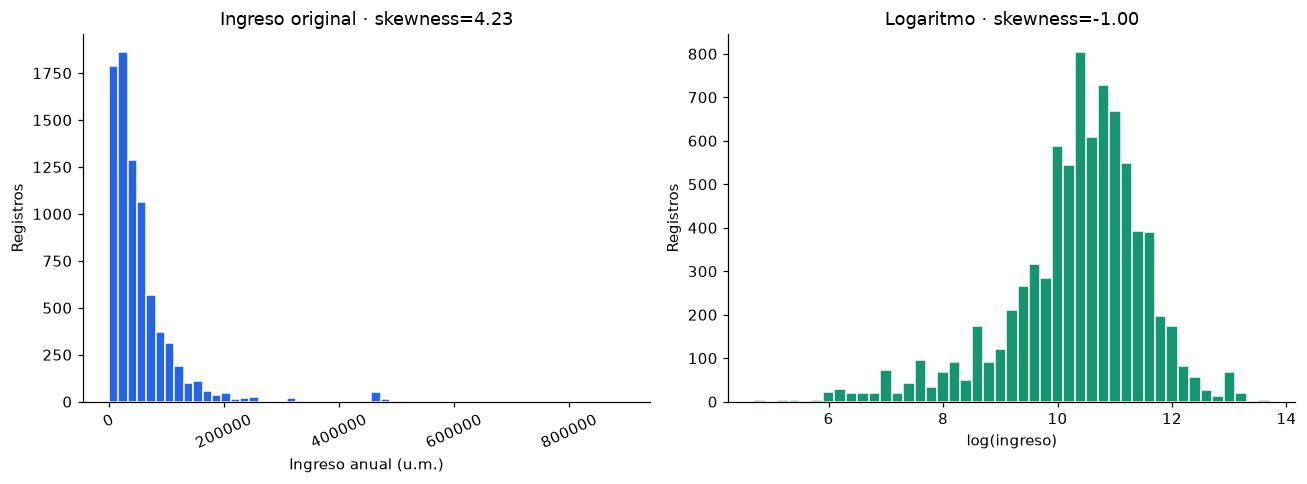

In [28]:
log_y_dev = np.log(y_dev)
skewness = pd.Series({'Ingreso original':y_dev.skew(), 'Logaritmo del ingreso':log_y_dev.skew()},name='Skewness')
display(skewness.to_frame())
display(y_dev.describe(percentiles=[.01,.25,.5,.75,.95,.99]).to_frame('Ingreso anual (u.m.)'))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].hist(y_dev,bins=55,color=COLORS[1],edgecolor='white')
axes[0].set(title=f'Ingreso original · skewness={y_dev.skew():.2f}',xlabel='Ingreso anual (u.m.)',ylabel='Registros')
axes[0].ticklabel_format(style='plain',axis='x')
axes[0].tick_params(axis='x',rotation=25)
axes[1].hist(log_y_dev,bins=45,color=COLORS[2],edgecolor='white')
axes[1].set(title=f'Logaritmo · skewness={log_y_dev.skew():.2f}',xlabel='log(ingreso)',ylabel='Registros')
plt.tight_layout()
plt.show()

### Interpretación de la distribución
En desarrollo, la skewness pasa de **4,229** para el ingreso original a **−1,002** para su logaritmo. Este cambio de sentido se debe a que la cola de ingresos altos se comprime, mientras que persiste una cola hacia ingresos muy bajos. 

## 4. Pipeline y candidatos 
Se mantienen los mismos predictores y el mismo preprocesamiento en ambas regresiones para aislar el efecto de transformar el objetivo.

- **Numéricas:** imputación por mediana, indicador de ausencia y estandarización. 
- **Categóricas:** imputación por la categoría más frecuente y one-hot encoding.
- **Regresor:** `LinearRegression` sin regularización ni ajuste de hiperparámetros.
- **Objetivo transformado:** `TransformedTargetRegressor` envuelve el pipeline, aplica `log` al entrenar y `exp` al predecir. 

Se agrega una referencia que predice siempre la mediana de los ingresos de entrenamiento. 

`sex` y `race` se incluyen entre las entradas de acuerdo con la consigna y se auditan después.

In [29]:
def make_linear_pipeline():
    numeric_pipeline = Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True)),
        ('scaler',StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ('imputer',SimpleImputer(strategy='most_frequent')),
        ('onehot',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('numeric',numeric_pipeline,NUMERIC),
        ('categorical',categorical_pipeline,CATEGORICAL),
    ])
    return Pipeline([('preprocess',preprocess),('regressor',LinearRegression())])

models = {
    'Baseline mediana': DummyRegressor(strategy='median'),
    'Lineal original': make_linear_pipeline(),
    'Lineal log': TransformedTargetRegressor(
        regressor=make_linear_pipeline(),func=np.log,inverse_func=np.exp,check_inverse=True),
}

def metrics(y_true,pred):
    return {'MAE':mean_absolute_error(y_true,pred),
            'RMSE':mean_squared_error(y_true,pred)**.5,
            'R2':r2_score(y_true,pred),
            'MedAE':median_absolute_error(y_true,pred),
            'Error medio':float(np.mean(np.asarray(pred)-np.asarray(y_true)))}

print('Candidatos:',list(models))
print('Error medio = predicción − ingreso real; negativo implica subestimación en promedio.')

Candidatos: ['Baseline mediana', 'Lineal original', 'Lineal log']
Error medio = predicción − ingreso real; negativo implica subestimación en promedio.


## 5. Validación cruzada sin leakage 
Para cada candidato y cada fold se clona un pipeline nuevo, se ajusta exclusivamente con las filas de entrenamiento y se predicen las de validación. Ningún imputador, escalador o encoder se ajusta antes del bucle.

Se usan exactamente los mismos folds para todos los candidatos. Se guardan predicciones fuera de fold (OOF) para cada registro de desarrollo, métricas por fold y un resumen global OOF. En el cual, el desvío entre folds nos da la variabilidad.

El criterio de selección es el menor MAE medio de validación entre las dos regresiones. RMSE y R² se reportan como diagnósticos complementarios. No se recortan predicciones negativas del modelo original: se contabilizan para hacer visible esa limitación.

In [30]:
cv_rows=[]
oof={name:np.full(len(X_dev),np.nan) for name in models}
validation_hits=np.zeros(len(X_dev),dtype=int)
leakage_checks=[]
for fold,(train_pos,val_pos) in enumerate(folds,1):
    validation_hits[val_pos]+=1
    for name,template in models.items():
        fitted=clone(template)
        fitted.fit(X_dev.iloc[train_pos],y_dev.iloc[train_pos])
        pred=fitted.predict(X_dev.iloc[val_pos])
        oof[name][val_pos]=pred
        cv_rows.append({'Modelo':name,'Fold':fold,**metrics(y_dev.iloc[val_pos],pred),
                        'Predicciones negativas':int((pred<0).sum())})
        if name=='Lineal original':
            learned=fitted.named_steps['preprocess'].named_transformers_['numeric'].named_steps['imputer'].statistics_
            expected=X_dev.iloc[train_pos][NUMERIC].median().to_numpy()
            assert np.allclose(learned,expected)
            leakage_checks.append({'Fold':fold,'Mediana horas aprendida':learned[1],
                                   'Mediana horas de entrenamiento':expected[1]})
assert np.all(validation_hits==1)
assert all(np.isfinite(pred).all() for pred in oof.values())
cv_results=pd.DataFrame(cv_rows)
cv_summary=cv_results.groupby('Modelo').agg(
    MAE_medio=('MAE','mean'),MAE_desvio=('MAE','std'),
    RMSE_medio=('RMSE','mean'),R2_medio=('R2','mean'),
    Predicciones_negativas=('Predicciones negativas','sum')).sort_values('MAE_medio')
oof_summary=pd.DataFrame({name:metrics(y_dev,pred) for name,pred in oof.items()}).T
print('Resultados por fold:')
display(cv_results)
print('Promedios y variabilidad entre folds:')
display(cv_summary)
print('Métricas OOF agrupadas (ponderan cada fila, no cada fold):')
display(oof_summary)
print('Verificación de medianas aprendidas exclusivamente en entrenamiento:')
display(pd.DataFrame(leakage_checks))
regressions=['Lineal original','Lineal log']
selected_name=cv_summary.loc[regressions,'MAE_medio'].idxmin()
mae_original=cv_summary.loc['Lineal original','MAE_medio']
mae_log=cv_summary.loc['Lineal log','MAE_medio']
improvement=100*(mae_original-mae_log)/mae_original
print(f'Selección por CV: {selected_name}. Cambio de MAE original → log: {improvement:.2f}% de reducción.')

Resultados por fold:


,Modelo,Fold,MAE,RMSE,R2,MedAE,Error medio,Predicciones negativas
0,Baseline mediana,1,"37,784.127","73,799.075",-0.081,"22,100.000","-20,245.221",0
1,Lineal original,1,"31,881.365","60,991.313",0.261,"20,277.402","-2,340.744",104
2,Lineal log,1,"30,463.527","63,628.285",0.196,"14,547.546","-14,064.075",0
3,Baseline mediana,2,"36,259.104","67,627.932",-0.079,"22,800.000","-18,303.072",0
4,Lineal original,2,"30,513.246","54,624.401",0.296,"19,572.186",129.219,101
5,Lineal log,2,"29,759.796","59,805.796",0.156,"14,205.547","-8,350.830",0
6,Baseline mediana,3,"34,883.298","66,019.747",-0.056,"22,000.000","-15,224.836",0
7,Lineal original,3,"30,240.833","54,107.178",0.291,"19,989.415","2,778.026",70
8,Lineal log,3,"27,885.919","56,296.780",0.232,"13,503.792","-9,130.166",0
9,Baseline mediana,4,"33,618.254","62,848.555",-0.068,"21,080.000","-15,872.929",0


Promedios y variabilidad entre folds:


,MAE_medio,MAE_desvio,RMSE_medio,R2_medio,Predicciones_negativas
Modelo,,,,,
Lineal log,"29,483.291","1,755.725","60,789.567",0.182,0
Lineal original,"31,216.456","1,618.710","57,423.600",0.271,459
Baseline mediana,"36,358.983","2,241.038","69,621.101",-0.072,0


Métricas OOF agrupadas (ponderan cada fila, no cada fold):


,MAE,RMSE,R2,MedAE,Error medio
Baseline mediana,"36,350.757","69,809.110",-0.072,"22,000.000","-18,039.958"
Lineal original,"31,209.532","57,616.910",0.270,"19,995.514",26.477
Lineal log,"29,478.066","60,948.842",0.183,"14,018.984","-11,116.483"


Verificación de medianas aprendidas exclusivamente en entrenamiento:


,Fold,Mediana horas aprendida,Mediana horas de entrenamiento
0,1,40.000,40.000
1,2,40.000,40.000
2,3,40.000,40.000
3,4,40.000,40.000
4,5,40.000,40.000


Selección por CV: Lineal log. Cambio de MAE original → log: 5.55% de reducción.


Modelo,Baseline mediana,Lineal log,Lineal original,Diferencia log − original
Fold,,,,
1,"37,784.127","30,463.527","31,881.365","-1,417.838"
2,"36,259.104","29,759.796","30,513.246",-753.450
3,"34,883.298","27,885.919","30,240.833","-2,354.914"
4,"33,618.254","27,569.937","29,713.640","-2,143.703"
5,"39,250.133","31,737.274","33,733.197","-1,995.923"


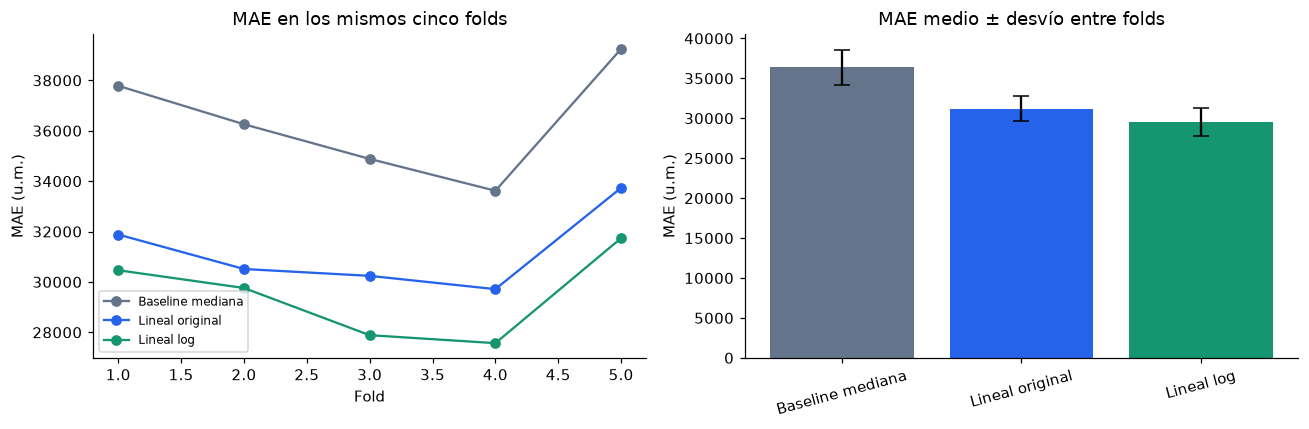

In [31]:
paired=cv_results.pivot(index='Fold',columns='Modelo',values='MAE')
paired['Diferencia log − original']=paired['Lineal log']-paired['Lineal original']
display(paired)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,color in zip(models,COLORS):
    t=cv_results[cv_results.Modelo.eq(name)]
    axes[0].plot(t.Fold,t.MAE,'-o',label=name,color=color)
axes[0].set(title='MAE en los mismos cinco folds',xlabel='Fold',ylabel='MAE (u.m.)')
axes[0].legend(fontsize=8)
order=list(models)
axes[1].bar(order,cv_summary.loc[order,'MAE_medio'],
            yerr=cv_summary.loc[order,'MAE_desvio'],color=COLORS,capsize=5)
axes[1].set(title='MAE medio ± desvío entre folds',ylabel='MAE (u.m.)')
axes[1].tick_params(axis='x',rotation=15)
plt.tight_layout()
plt.show()

### Comparación e interpretación
**Se selecciona la regresión con logaritmo**, con MAE CV medio de **29.483,3 u.m.**, frente a **31.216,5** de la regresión original y **36.359,0** de la mediana. 

La mejora no es general para todas las métricas: el RMSE medio pasa de **57.423,6 a 60.789,6**, y el R² medio baja de **0,271 a 0,182**.

La selección por MAE se realiza antes de evaluar prueba. El promedio de MAE entre folds y el MAE OOF global difieren levemente porque los folds no tienen exactamente el mismo tamaño.

Al entrenar en log, la regresión minimiza errores cuadrados logarítmicos. La exponencial de la predicción estima un centro geométrico condicional.

No se aplica una corrección de retransformación (*smearing*) porque se comparan las dos especificaciones declaradas. Una corrección futura debería estimarse dentro de los folds y volver a validarse, sin ajustar con el test.

## 6. Modelo final y prueba reservada
Se entrena una instancia nueva del candidato seleccionado con todos los datos de desarrollo. Esa es la versión final auditada. El conjunto de prueba se usa ahora para medir desempeño y disparidades, sin modificar la elección ni los parámetros según sus resultados.

También se evalúa una mediana aprendida exclusivamente en desarrollo como referencia. 

Modelo final: Lineal log


,MAE,RMSE,R2,MedAE,Error medio
Lineal log,"29,309.643","63,827.084",0.181,"13,158.561","-11,279.327"
Baseline mediana,"35,940.424","72,950.282",-0.070,"21,060.000","-18,606.911"


Predicciones negativas en prueba: 0
Tamaño de prueba: 2007


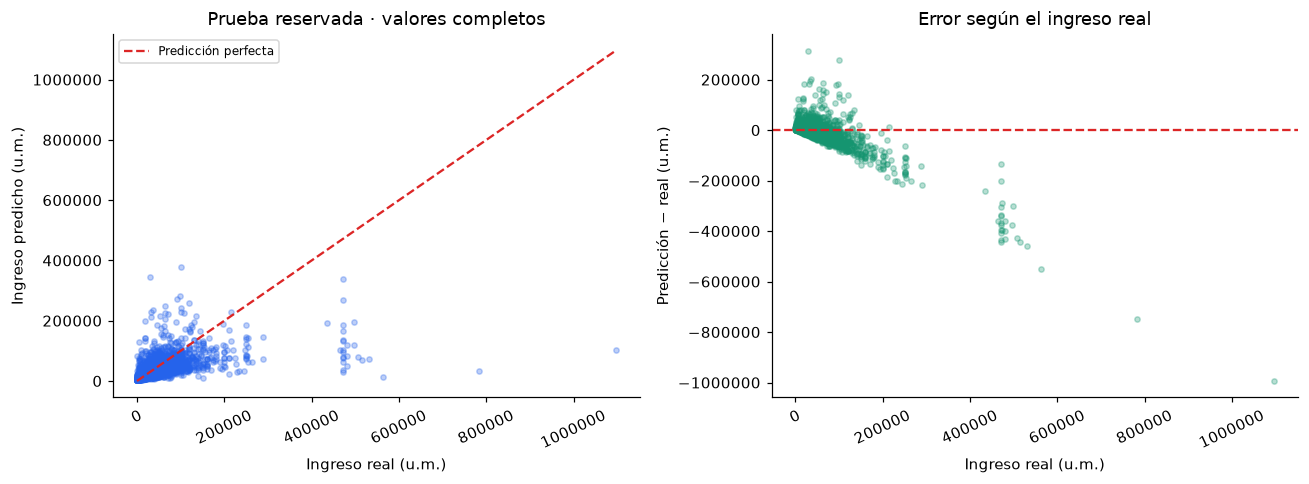

In [32]:
final_model=clone(models[selected_name]).fit(X_dev,y_dev)
pred_test=final_model.predict(X_test)
baseline_final=DummyRegressor(strategy='median').fit(X_dev,y_dev)
pred_baseline=baseline_final.predict(X_test)
test_summary=pd.DataFrame({selected_name:metrics(y_test,pred_test),
                           'Baseline mediana':metrics(y_test,pred_baseline)}).T
print('Modelo final:',selected_name)
display(test_summary)
print('Predicciones negativas en prueba:',int((pred_test<0).sum()))
print('Tamaño de prueba:',len(y_test))
audit=X_test.copy()
audit['income_real']=y_test.to_numpy()
audit['income_pred']=pred_test
audit['error']=pred_test-y_test.to_numpy()
audit['abs_error']=np.abs(audit.error)
audit['profile_group']=g_test
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
upper=max(float(y_test.max()),float(pred_test.max()))
axes[0].scatter(y_test,pred_test,s=12,alpha=.3,color=COLORS[1])
axes[0].plot([0,upper],[0,upper],'--',color='#dc2626',label='Predicción perfecta')
axes[0].set(xlabel='Ingreso real (u.m.)',ylabel='Ingreso predicho (u.m.)',title='Prueba reservada · valores completos')
axes[0].ticklabel_format(style='plain',axis='both')
axes[0].tick_params(axis='x',rotation=25)
axes[0].legend(fontsize=8)
axes[1].scatter(y_test,audit.error,s=12,alpha=.3,color=COLORS[2])
axes[1].axhline(0,color='#dc2626',ls='--')
axes[1].set(xlabel='Ingreso real (u.m.)',ylabel='Predicción − real (u.m.)',title='Error según el ingreso real')
axes[1].ticklabel_format(style='plain',axis='both')
axes[1].tick_params(axis='x',rotation=25)
plt.tight_layout()
plt.show()

**Resultado de prueba:** la versión final alcanza **MAE=29.309,6 u.m., RMSE=63.827,1 u.m. y R²=0,181**. La mediana obtiene MAE=35.940,4, por lo que la regresión aporta una reducción de aproximadamente 18,45% frente a esa referencia. El resultado de prueba es cercano al MAE CV, sin que una única partición garantice estabilidad futura.

El error medio es **−11.279,3 u.m.**: el modelo subestima el ingreso promedio. Los gráficos muestran errores negativos grandes para ingresos altos acordes con la compresión del logaritmo. 

## 7. Auditoría por sexo y raza 
Las métricas se calculan **solo con las predicciones del modelo final sobre prueba**. Se reportan tamaño de muestra, ingreso medio, MAE, RMSE, error medio firmado y MAE dividido por el ingreso medio del grupo. Este último cociente contextualiza la escala; no es MAPE ni una métrica suficiente de equidad.

Se incluyen intervalos bootstrap al 95% para MAE y error medio. El remuestreo se hace por perfiles dentro de cada subgrupo, conservando juntas las filas del mismo perfil. Los intervalos reflejan variabilidad muestral condicionada al modelo ya entrenado, sin incluir incertidumbre por volver a entrenarlo. Se usan 1.000 repeticiones, con semilla fija.


In [33]:
BOOTSTRAPS=1000
rng=np.random.default_rng(RANDOM_STATE)

def cluster_bootstrap_errors(frame):
    aggregated=frame.groupby('profile_group').agg(
        abs_sum=('abs_error','sum'),error_sum=('error','sum'),n=('error','size'))
    values=aggregated.to_numpy()
    draws=rng.integers(0,len(values),size=(BOOTSTRAPS,len(values)))
    sampled=values[draws].sum(axis=1)
    return sampled[:,0]/sampled[:,2],sampled[:,1]/sampled[:,2]

def subgroup_table(variable):
    rows=[];boot={}
    for group,g in audit.groupby(variable,dropna=False):
        mae_draws,bias_draws=cluster_bootstrap_errors(g)
        boot[group]=mae_draws
        mae=float(g.abs_error.mean());mean_income=float(g.income_real.mean())
        rows.append({'Grupo':group,'n':len(g),'Perfiles':g.profile_group.nunique(),
                     'Ingreso medio':mean_income,'MAE':mae,
                     'MAE IC95 inf':np.quantile(mae_draws,.025),
                     'MAE IC95 sup':np.quantile(mae_draws,.975),
                     'RMSE':float(np.sqrt((g.error**2).mean())),
                     'Error medio':float(g.error.mean()),
                     'Error IC95 inf':np.quantile(bias_draws,.025),
                     'Error IC95 sup':np.quantile(bias_draws,.975),
                     'MAE/ingreso medio':mae/mean_income})
    return pd.DataFrame(rows).set_index('Grupo'),boot

sex_metrics,sex_boot=subgroup_table('sex')
race_metrics,race_boot=subgroup_table('race')
print('Auditoría por sex:')
display(sex_metrics)
print('Auditoría por race:')
display(race_metrics)
# El MAE global debe coincidir con el promedio ponderado de los MAE por subgrupo.
for table in [sex_metrics,race_metrics]:
    assert np.isclose(np.average(table.MAE,weights=table.n),mean_absolute_error(y_test,pred_test))
if {'Male','Female'}.issubset(sex_metrics.index):
    difference=sex_metrics.loc['Male','MAE']-sex_metrics.loc['Female','MAE']
    diff_boot=sex_boot['Male']-sex_boot['Female']
    print(f'Diferencia MAE Male − Female: {difference:,.1f} u.m.; IC95 bootstrap por perfiles: '
          f'[{np.quantile(diff_boot,.025):,.1f}, {np.quantile(diff_boot,.975):,.1f}]')
    print(f'Razón descriptiva MAE Male/Female: {sex_metrics.loc["Male","MAE"]/sex_metrics.loc["Female","MAE"]:.3f}')
print('Las categorías se conservan exactamente como figuran en el archivo.')

Auditoría por sex:


,n,Perfiles,Ingreso medio,MAE,MAE IC95 inf,MAE IC95 sup,RMSE,Error medio,Error IC95 inf,Error IC95 sup,MAE/ingreso medio
Grupo,,,,,,,,,,,
Female,1003,852,"44,048.843","23,922.161","20,932.587","27,005.691","54,093.486","-9,930.964","-13,298.806","-6,550.832",0.543
Male,1004,855,"65,274.402","34,691.759","30,800.315","39,185.398","72,253.338","-12,626.346","-17,465.019","-8,300.308",0.531


Auditoría por race:


,n,Perfiles,Ingreso medio,MAE,MAE IC95 inf,MAE IC95 sup,RMSE,Error medio,Error IC95 inf,Error IC95 sup,MAE/ingreso medio
Grupo,,,,,,,,,,,
Asian,84,74,"58,872.619","33,188.986","24,312.637","45,094.724","59,161.528","-11,095.591","-24,563.037",426.970,0.564
Black,483,436,"41,736.315","21,863.789","18,527.847","25,665.188","45,856.288","-6,531.561","-11,001.390","-2,742.989",0.524
Other or multiple,80,76,"37,592.500","17,391.096","11,115.898","25,398.539","36,585.357","-5,674.939","-13,405.242","1,709.954",0.463
White,1360,1121,"60,003.787","32,415.501","28,716.792","36,137.169","70,500.168","-13,306.500","-17,606.389","-9,452.184",0.540


Diferencia MAE Male − Female: 10,769.6 u.m.; IC95 bootstrap por perfiles: [5,937.6, 16,352.9]
Razón descriptiva MAE Male/Female: 1.450
Las categorías se conservan exactamente como figuran en el archivo.


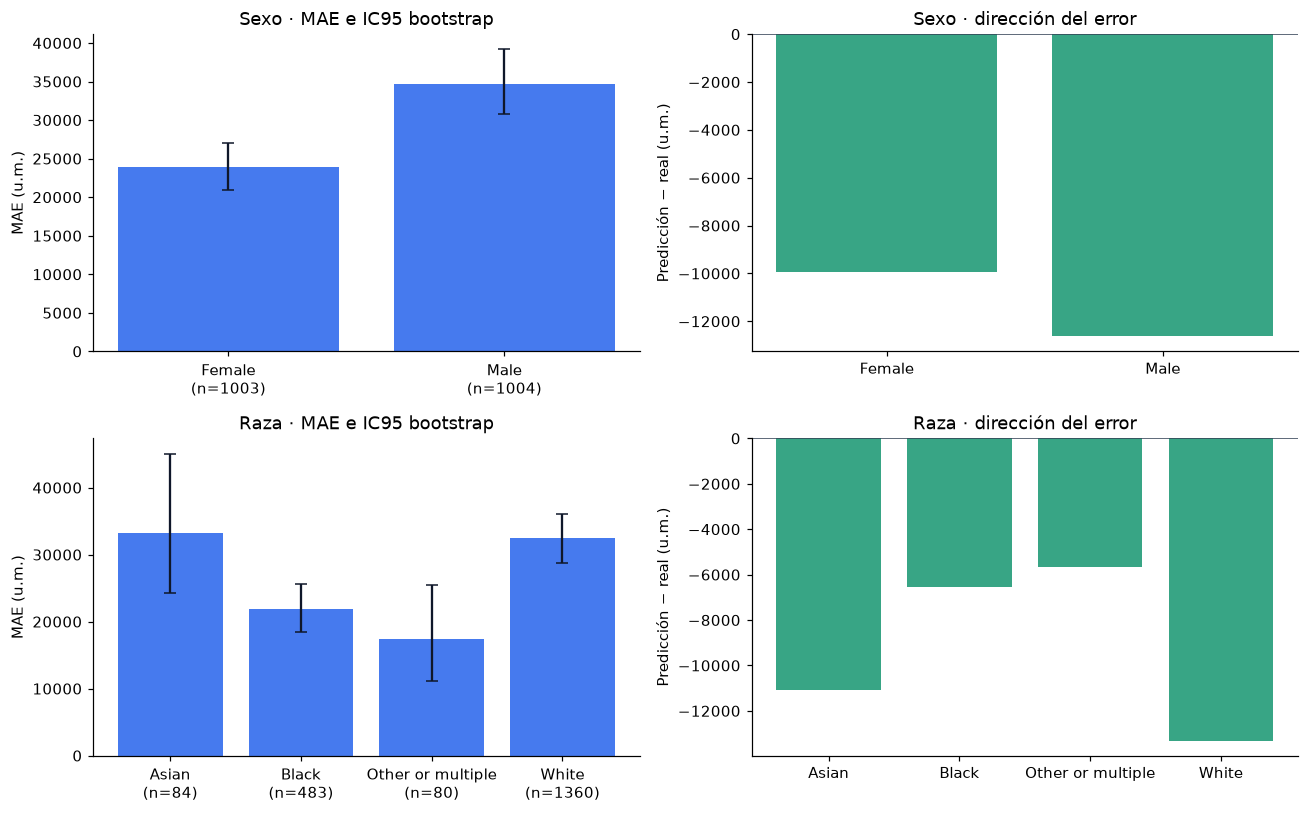

In [34]:
fig,axes=plt.subplots(2,2,figsize=(12,7.5))
for row,(name,table) in enumerate([('Sexo',sex_metrics),('Raza',race_metrics)]):
    positions=np.arange(len(table))
    axes[row,0].bar(positions,table.MAE,color=COLORS[1],alpha=.85)
    axes[row,0].errorbar(positions,table.MAE,
        yerr=np.vstack([table.MAE-table['MAE IC95 inf'],table['MAE IC95 sup']-table.MAE]),
        fmt='none',ecolor='#0f172a',capsize=4)
    axes[row,0].set_xticks(positions,[f'{g}\n(n={int(table.loc[g,"n"])})' for g in table.index])
    axes[row,0].set(title=f'{name} · MAE e IC95 bootstrap',ylabel='MAE (u.m.)')
    axes[row,1].bar(positions,table['Error medio'],color=COLORS[2],alpha=.85)
    axes[row,1].axhline(0,color='#334155',lw=1)
    axes[row,1].set_xticks(positions,table.index)
    axes[row,1].set(title=f'{name} · dirección del error',ylabel='Predicción − real (u.m.)')
plt.tight_layout()
plt.show()

### Hallazgos de la auditoría y acciones propuestas
**Sexo.** El MAE es **23.922,2** para Female (n=1.003) y **34.691,8** para Male (n=1.004). La diferencia Male − Female es **10.769,6 u.m.**, con IC95 bootstrap por perfiles de **[5.937,6; 16.352,9]**. La razón descriptiva de MAE es 1,45. 

La escala de ingresos también difiere: sus ingresos medios son 44.048,8 y 65.274,4. El cociente MAE/ingreso medio es **54,3% en Female y 53,1% en Male**, mucho más parecido que el MAE absoluto. 

Ambos grupos presentan subestimación media: −9.931,0 y −12.626,3 u.m.; los intervalos de error medio no incluyen cero. Es un sesgo estadístico de calibración en estos grupos, cuya causa no queda identificada por esta auditoría.

**Raza.** Los MAE son **33.189,0** para Asian (n=84), **21.863,8** para Black (n=483), **17.391,1** para Other or multiple (n=80) y **32.415,5** para White (n=1.360). 

El error medio estimado es negativo en las cuatro categorías, pero los IC95 de Asian y Other or multiple incluyen cero. 

**Conclusión de la auditoría:** hay disparidades de error y señales de subestimación sistemática, pero estas tablas no prueban discriminación causal. 

Antes de cualquier uso fuera del ejercicio sería necesario ampliar subgrupos pequeños, revisar calidad y faltantes por grupo, evaluar relaciones no lineales y errores en ingresos extremos y comparar especificaciones con y sin variables sensibles mediante validación. Por lo tanto, excluir `sex` o `race` no garantiza equidad porque otras variables pueden actuar como proxies. 

## 8. Model Card del modelo final — Parte 2b
La tarjeta siguiente se genera a partir de las métricas de esta ejecución. Documenta el modelo ajustado únicamente con desarrollo y auditado sobre prueba; no describe un hipotético modelo reentrenado con todas las filas.

In [35]:
m=test_summary.loc[selected_name]
rows=['| Variable sensible | Grupo | n prueba | MAE (u.m.) | Error medio (u.m.) |',
      '|---|---|---:|---:|---:|']
for variable,table in [('sex',sex_metrics),('race',race_metrics)]:
    for group,row in table.iterrows():
        rows.append(f'| {variable} | {group} | {int(row["n"])} | {row["MAE"]:,.1f} | {row["Error medio"]:,.1f} |')
card=f"""### Model Card — Regresión de ingreso anual


**Datos:** Excel proporcionado, {len(df):,} filas. {len(X_dev):,} para desarrollo y {len(X_test):,} para prueba; perfiles idénticos separados por grupos. No se cuenta con fecha, moneda, diseño muestral ni procedencia más detallada.

**Entradas:** age, hours_per_week, education, employer_type, marital_status, sex, race y born_in_us. Requiere el mismo significado y formato de variables. Faltantes imputados dentro del pipeline.

**Salida:** estimación puntual del ingreso anual en unidades del archivo; no es una probabilidad ni un intervalo individual de predicción.

**Modelo:** {selected_name}, regresión lineal con imputación, estandarización numérica y one-hot. {('Se ajusta log(income) y se aplica exp a la predicción.' if selected_name=='Lineal log' else 'Se ajusta directamente income.')} Se incluyen atributos sensibles para este análisis académico.

**Selección y validación:** menor MAE medio entre las dos regresiones mediante GroupKFold de 5 folds dentro de desarrollo. MAE CV={cv_summary.loc[selected_name,'MAE_medio']:,.1f} ± {cv_summary.loc[selected_name,'MAE_desvio']:,.1f} (desvío entre folds). Prueba independiente por perfiles, sin ajustar decisiones con sus resultados.

**Desempeño global en prueba:** MAE={m['MAE']:,.1f}; RMSE={m['RMSE']:,.1f}; R²={m['R2']:.3f}; error medio={m['Error medio']:,.1f} u.m. Baseline mediana: MAE={test_summary.loc['Baseline mediana','MAE']:,.1f} u.m.

**Desempeño por subgrupo:** error medio negativo implica subestimación.

{chr(10).join(rows)}

**Limitaciones:** objetivo asimétrico, errores elevados para algunos ingresos altos, posible subestimación sistemática, categorías y subgrupos de representación desigual, metadatos de origen insuficientes y ausencia de validación temporal o externa. Los intervalos bootstrap de la auditoría son condicionales al modelo; no aseguran equidad ni cuantifican todas las fuentes de incertidumbre.

**Revisión futura:** controlar calidad y drift de entradas, MAE y error firmado por grupos cuando se observen nuevos ingresos; validar cambios del modelo con datos nuevos antes de adoptarlos. El presente artefacto no está desplegado.
"""
display(Markdown(card))

### Model Card — Regresión de ingreso anual


**Datos:** Excel proporcionado, 10,000 filas. 7,993 para desarrollo y 2,007 para prueba; perfiles idénticos separados por grupos. No se cuenta con fecha, moneda, diseño muestral ni procedencia más detallada.

**Entradas:** age, hours_per_week, education, employer_type, marital_status, sex, race y born_in_us. Requiere el mismo significado y formato de variables. Faltantes imputados dentro del pipeline.

**Salida:** estimación puntual del ingreso anual en unidades del archivo; no es una probabilidad ni un intervalo individual de predicción.

**Modelo:** Lineal log, regresión lineal con imputación, estandarización numérica y one-hot. Se ajusta log(income) y se aplica exp a la predicción. Se incluyen atributos sensibles para este análisis académico.

**Selección y validación:** menor MAE medio entre las dos regresiones mediante GroupKFold de 5 folds dentro de desarrollo. MAE CV=29,483.3 ± 1,755.7 (desvío entre folds). Prueba independiente por perfiles, sin ajustar decisiones con sus resultados.

**Desempeño global en prueba:** MAE=29,309.6; RMSE=63,827.1; R²=0.181; error medio=-11,279.3 u.m. Baseline mediana: MAE=35,940.4 u.m.

**Desempeño por subgrupo:** error medio negativo implica subestimación.

| Variable sensible | Grupo | n prueba | MAE (u.m.) | Error medio (u.m.) |
|---|---|---:|---:|---:|
| sex | Female | 1003 | 23,922.2 | -9,931.0 |
| sex | Male | 1004 | 34,691.8 | -12,626.3 |
| race | Asian | 84 | 33,189.0 | -11,095.6 |
| race | Black | 483 | 21,863.8 | -6,531.6 |
| race | Other or multiple | 80 | 17,391.1 | -5,674.9 |
| race | White | 1360 | 32,415.5 | -13,306.5 |

**Limitaciones:** objetivo asimétrico, errores elevados para algunos ingresos altos, posible subestimación sistemática, categorías y subgrupos de representación desigual, metadatos de origen insuficientes y ausencia de validación temporal o externa. Los intervalos bootstrap de la auditoría son condicionales al modelo; no aseguran equidad ni cuantifican todas las fuentes de incertidumbre.

**Revisión futura:** controlar calidad y drift de entradas, MAE y error firmado por grupos cuando se observen nuevos ingresos; validar cambios del modelo con datos nuevos antes de adoptarlos. El presente artefacto no está desplegado.


## 9. Conclusiones
La hipótesis se sostiene en relación con el MAE: el logaritmo reduce la asimetría del objetivo y mejora el MAE CV un 5,55% respecto del modelo original. Sin embargo, empeora RMSE y R² de validación y produce subestimación promedio. La transformación es adecuada para el criterio de selección elegido, no una mejora universal.

En prueba, el MAE de 29.309,6 u.m. mejora la referencia de mediana, pero el R² de 0,181 y la subestimación de ingresos altos muestran capacidad predictiva limitada. La auditoría por sexo y raza encuentra diferencias absolutas de error que deben contextualizarse por ingresos y tamaño muestral. La Model Card documenta estos resultados y limita el alcance a un ejercicio académico.


In [36]:
assert TARGET not in FEATURES
assert set(g_dev).isdisjoint(set(g_test))
assert np.all(validation_hits==1)
assert len(pred_test)==len(y_test) and np.isfinite(pred_test).all()
assert len(cv_results)==5*len(models)
print('Verificaciones correctas: cinco folds por candidato, OOF completa y perfiles separados.')
print('Modelo auditado:',selected_name,'; entrenado con',len(X_dev),'filas; prueba:',len(X_test),'filas.')

Verificaciones correctas: cinco folds por candidato, OOF completa y perfiles separados.
Modelo auditado: Lineal log ; entrenado con 7993 filas; prueba: 2007 filas.
